# VLA book renders 5 — action expert query / key / value bars
Minimal notebook, streamlined from `p58_61.ipynb`: run one denoising step of π0's action expert, capture the
queries, keys and values of one attention head for the 51 suffix tokens (1 state token + 50 action tokens),
and save them as bar images with transparent backgrounds.

In [1]:
import os
import colorsys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageCms
from datasets import load_dataset

import torch
from openpi.training import config as _config
from openpi.policies import policy_config as _policy_config
from openpi.models import model as _model
from openpi.models_pytorch.pi0_pytorch import make_att_2d_masks

## Config

In [2]:
EPISODE_IDX = 0
FRAME_IDX   = 150
PROMPT      = "uncap the pen"
NOISE_SEED  = 42             # same fixed noise as the other notebooks

LAYER, HEAD = 8, 6           # action expert attention head

# Suffix token rows to render. Row 0 is the state token, rows 1-50 are the 50 action tokens.
# None = transparent spacer row.
ROWS = [0, 1, 2, None, 48, 49, 50]

# Bar colors (RGB 0-255), as in p58_61
STATE_COLOR  = (135, 0, 0)                               # dark red
ACTION_COLOR = tuple(0.7 * np.array([250, 208, 226]))    # dusty pink
BAR_STYLE = dict(saturation_boost=2.0, min_saturation=0.4, min_value=0.3, brightness_range=0.85)

# Bar geometry (pixels) - same as the PaliGemma bars
BAR_WIDTH = 2180
BAR_ROW_H = 40
BAR_GAP   = 12               # transparent gap between rows in the stacked image

checkpoint_dir = "/home/stephen/openpi/pi0_aloha_pen_uncap_pytorch"
save_dir = "/home/stephen/Stephencwelch Dropbox/welch_labs/ai_book_vol_2/3_vla/graphics"
bar_dir = save_dir + "/expert_bars"
os.makedirs(bar_dir, exist_ok=True)

SRGB_ICC = ImageCms.ImageCmsProfile(ImageCms.createProfile("sRGB")).tobytes()

## Load episode + model

In [3]:
ds = load_dataset("physical-intelligence/aloha_pen_uncap_diverse", split="train")
episode = ds.select(np.where(np.array(ds["episode_index"]) == EPISODE_IDX)[0])
print(f"{episode.num_rows} frames")

policy = _policy_config.create_trained_policy(_config.get_config("pi0_aloha_pen_uncap"), checkpoint_dir)
pt_model = policy._model
device = torch.device(policy._pytorch_device)
print(f"device: {device}")
pt_model.paligemma_with_expert.paligemma.language_model.config._attn_implementation = "eager"
pt_model.paligemma_with_expert.gemma_expert.model.config._attn_implementation = "eager"

def frame_to_obs(frame):
    to_chw = lambda img: np.array(img).transpose(2, 0, 1)   # PIL HWC -> CHW
    return {
        "images": {cam: to_chw(frame[f"observation.images.{cam}"])
                   for cam in ["cam_high", "cam_left_wrist", "cam_right_wrist"]},
        "state": np.array(frame["observation.state"]),
        "prompt": PROMPT,
    }

Resolving data files:   0%|          | 0/123 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/123 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/123 [00:00<?, ?it/s]

300 frames
device: cuda


## Capture queries, keys and values
Runs the first denoising step (t = 1.0, the action tokens are pure noise) and grabs one head of one action expert layer.

In [4]:
def _batched(x):
    if isinstance(x, dict):
        return {k: _batched(v) for k, v in x.items()}
    return torch.from_numpy(np.array(x)).to(device)[None, ...]

# note: the input transform modifies its argument in place, so always hand it a fresh observation
_inputs = policy._input_transform(frame_to_obs(episode[FRAME_IDX]))
_observation = _model.Observation.from_dict(_batched(_inputs))
_images, _img_masks, _lang_tokens, _lang_masks, _state = pt_model._preprocess_observation(_observation, train=False)

noise = np.random.RandomState(NOISE_SEED).randn(50, 32).astype(np.float32)

cap = {}
attn_module = pt_model.paligemma_with_expert.gemma_expert.model.layers[LAYER].self_attn
grab = lambda name: (lambda module, inp, out: cap.__setitem__(name, out))
hooks = [attn_module.q_proj.register_forward_hook(grab("q")),
         attn_module.k_proj.register_forward_hook(grab("k")),
         attn_module.v_proj.register_forward_hook(grab("v"))]
try:
    with torch.no_grad():
        # images + prompt through PaliGemma once -> cache that the action expert attends to
        _pre_embs, _pre_pad, _pre_att = pt_model.embed_prefix(_images, _img_masks, _lang_tokens, _lang_masks)
        _att_4d = pt_model._prepare_attention_masks_4d(make_att_2d_masks(_pre_pad, _pre_att))
        _, _kv_cache = pt_model.paligemma_with_expert.forward(
            attention_mask=_att_4d, position_ids=torch.cumsum(_pre_pad, dim=1) - 1,
            past_key_values=None, inputs_embeds=[_pre_embs, None], use_cache=True)

        # one denoising step at t = 1.0
        x_t = torch.from_numpy(noise).to(device)[None, ...]
        timestep = torch.tensor([1.0], dtype=torch.float32, device=device)
        pt_model.denoise_step(_state, _pre_pad, _kv_cache, x_t, timestep)
finally:
    for h in hooks:
        h.remove()

to_np = lambda t: t.detach().float().cpu().numpy()
d = cap["k"].shape[-1]                                        # head dim (256); K and V are shared across heads
queries = to_np(cap["q"][0, :, HEAD * d:(HEAD + 1) * d])      # (51, 256)
keys    = to_np(cap["k"][0])                                  # (51, 256)
values  = to_np(cap["v"][0])                                  # (51, 256)
print(queries.shape, keys.shape, values.shape)

(51, 256) (51, 256) (51, 256)


## Render the bars
One bar per token: the state token in dark red, action tokens in pink. Saved as one stacked image per type
plus one PNG per row, all with transparent backgrounds.

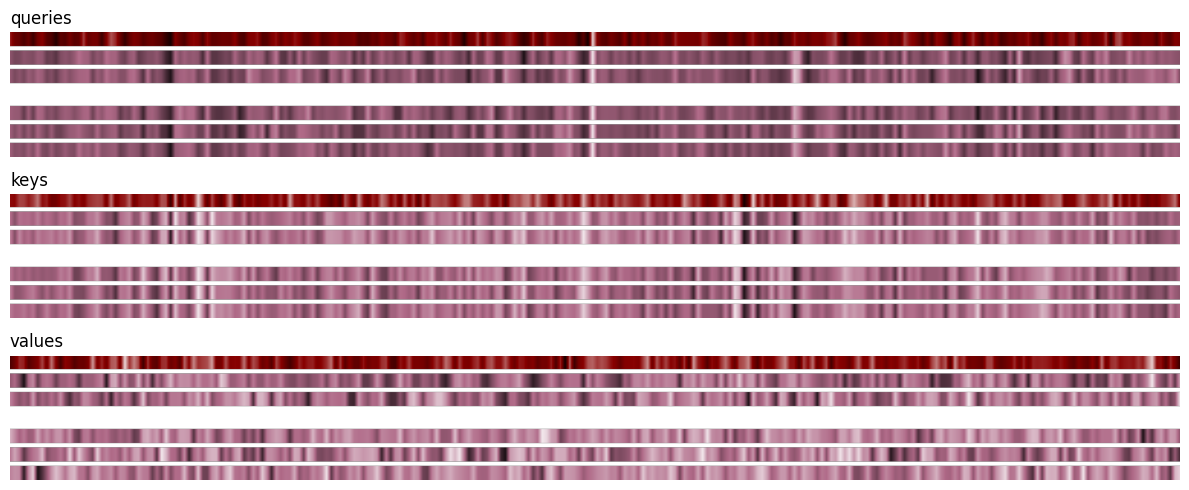

saved to /home/stephen/Stephencwelch Dropbox/welch_labs/ai_book_vol_2/3_vla/graphics/expert_bars


In [5]:
def boost_color(c, saturation_boost=1.0, min_saturation=0.0, min_value=0.0):
    h, s, v = colorsys.rgb_to_hsv(*c)
    s = max(min(1.0, s * saturation_boost), min_saturation)
    v = max(v, min_value)
    return np.array(colorsys.hsv_to_rgb(h, s, v), dtype=np.float32)

def render_bar(vec, color, width=BAR_WIDTH, height=BAR_ROW_H, brightness_range=0.85, **boost):
    """One vector -> (height, width, 4) uint8 RGBA. Low values go dark, high values go toward white."""
    c = boost_color(color, **boost)
    lo, hi = vec.min(), vec.max()
    norm = (vec - lo) / (hi - lo) if hi - lo > 1e-12 else np.full_like(vec, 0.5)
    x = np.interp(np.linspace(0, 1, width), np.linspace(0, 1, len(vec)), norm)[:, None]
    dark, bright = c * (1 - brightness_range), c + (1 - c) * brightness_range
    rgb = np.where(x <= 0.5, dark + 2 * x * (c - dark), c + 2 * (x - 0.5) * (bright - c))
    rgba = np.concatenate([np.clip(rgb, 0, 1), np.ones((width, 1))], axis=1)
    return np.broadcast_to((255 * rgba).round().astype(np.uint8), (height, width, 4)).copy()

def render_bars(vectors, colors, rows=ROWS, gap=BAR_GAP, **style):
    """Stack bars for `rows`; spacer rows (None) are left transparent."""
    bars = [np.zeros((BAR_ROW_H, BAR_WIDTH, 4), np.uint8) if r is None else render_bar(vectors[r], colors[r], **style)
            for r in rows]
    spacer = np.zeros((gap, BAR_WIDTH, 4), np.uint8)
    return np.vstack([p for b in bars for p in (b, spacer)][:-1]), bars

# one color per suffix token: row 0 = state, rows 1-50 = actions
token_colors = np.vstack([np.array(STATE_COLOR, dtype=np.float32)[None],
                          np.tile(np.array(ACTION_COLOR, dtype=np.float32), (len(queries) - 1, 1))]) / 255.

fig, axes = plt.subplots(3, 1, figsize=(12, 5))
for ax, (name, vectors) in zip(axes, [("queries", queries), ("keys", keys), ("values", values)]):
    stacked, bars = render_bars(vectors, token_colors, **BAR_STYLE)
    Image.fromarray(stacked).save(f"{bar_dir}/expert_{name}_stacked.png", icc_profile=SRGB_ICC)
    for i, (r, bar) in enumerate(zip(ROWS, bars)):
        if r is not None:
            Image.fromarray(bar).save(f"{bar_dir}/expert_{name}_{i:02d}_row{r:02d}.png", icc_profile=SRGB_ICC)
    ax.imshow(stacked, aspect="auto"); ax.set_title(name, loc="left"); ax.axis("off")
plt.tight_layout(); plt.show()
print(f"saved to {bar_dir}")